# Human-AI Review of Fraud Alerts (FiFAR)
In a bank, the fraud model does not act alone: suspicious applications (**alerts**) are reviewed by human fraud analysts, and there are not enough analysts to check every alert. This notebook asks: **which alerts should the model decide by itself, and which should go to an analyst?**

We use the **Financial Fraud Alert Review (FiFAR)** dataset, built by Feedzai on the same Base applications as notebook 02:
- **30,622 alerts** from months 3-7: the Base applications that Feedzai's own alert model (a LightGBM) flagged
- the decision of **50 synthetic fraud analysts** on every alert
- **capacity limits**: how many alerts each analyst can review

Our frozen model from notebook 02 (XGBoost) is reused unchanged. Nothing is retrained here.

## **1. Imports**

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from model_loading import load_model   # works on Windows too (see README, Prerequisites)
from sklearn.metrics import roc_auc_score, average_precision_score

# Plot settings (same as notebook 02)
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

## **2. Months Used**
Our model was trained on Base months 0-3, tuned on month 4 and had its threshold picked on month 5. FiFAR's alerts cover months 3-7, so:

| Months | Used for |
|---|---|
| 3 | **not used**: our model was trained on these applications, so its scores there are too optimistic |
| 4-6 | **history**: measuring how good each analyst is, and setting up the review policies |
| 7 | **test**: comparing the review policies (also FiFAR's own test month) |

Fairness uses the same age groups as notebook 02: **50+ vs under 50**.

In [2]:
DATA_DIR = '../data'
FIFAR_DIR = f'{DATA_DIR}/fifar'
TARGET = 'fraud_bool'

HISTORY_MONTHS = [4, 5, 6]
TEST_MONTHS = [7]
SEEDS = [0, 1, 2, 3, 4]

## **3. Load FiFAR**

In [3]:
alerts = pd.read_parquet(f'{FIFAR_DIR}/alert_data/processed_data/alerts.parquet')
expert_predictions = pd.read_parquet(f'{FIFAR_DIR}/synthetic_experts/expert_predictions.parquet')
ANALYSTS = list(expert_predictions.columns)

# both tables are indexed by case_id; put the analyst decisions in the same row order as the alerts
expert_predictions = expert_predictions.loc[alerts.index]

print(f'{len(alerts):,} alerts, {len(ANALYSTS)} analysts')
alerts.groupby('month').agg(alerts=(TARGET, 'size'), fraud_cases=(TARGET, 'sum'), fraud_rate=(TARGET, 'mean')).round(3)

30,622 alerts, 50 analysts


,alerts,fraud_cases,fraud_rate
month,,,
3,8282,806,0.097
4,7612,830,0.109
5,4871,665,0.137
6,5400,702,0.130
7,4457,711,0.160


In [4]:
# How the alerts were chosen: Feedzai's alert model flags every application above a fixed score
all_scores = pd.read_parquet(f'{FIFAR_DIR}/alert_data/processed_data/BAF_alert_model_score.parquet',
                             columns=[TARGET, 'model_score'])
alert_threshold = alerts['model_score'].min()
# this file has no month column; FiFAR's case_id is the row number after Base is sorted by month,
# so the case_id-th smallest month is that application's month
months_sorted = np.sort(pd.read_csv(f'{DATA_DIR}/Base.csv', usecols=['month'])['month'].to_numpy())
all_scores['month'] = months_sorted[all_scores.index]

rows = []
for month, part in all_scores.groupby('month'):
    flagged = part['model_score'] >= alert_threshold
    rows.append({'month': month, 'applications': len(part), 'alerts': flagged.sum(),
                 'FPR': flagged[part[TARGET] == 0].mean(), 'recall': flagged[part[TARGET] == 1].mean()})
print(f'Alert model threshold: {alert_threshold:.4f}')
pd.DataFrame(rows).set_index('month').round(3)

Alert model threshold: 0.0510


,applications,alerts,FPR,recall
month,,,,
3,150936,8282,0.050,0.579
4,127691,7612,0.054,0.572
5,119323,4871,0.036,0.471
6,108168,5400,0.044,0.484
7,96843,4457,0.039,0.498


**Findings**

How the numbers are derived:
- **Alert threshold.** FiFAR doesn't state the alert model's cut-off, so it is taken as the lowest `model_score` among the alerts: **0.0510**. Applying it to all 602,961 scored applications in months 3-7 gives exactly 30,622 alerts, matching the alert file month by month, so the alerts are exactly the applications scoring ≥ 0.0510.
- **FPR** = genuine applications alerted / all genuine applications; **recall** = fraud applications alerted / all fraud applications, per month. For example, in month 3: 7,476 of 149,544 genuine applications were alerted (FPR 0.050) and 806 of 1,392 fraud applications (recall 0.579).
- **Fraud rate among alerts** = fraud alerted / alerts: 3,714 / 30,622 = 12.1% overall, from 806 / 8,282 = 9.7% in month 3 to 711 / 4,457 = 16.0% in month 7.

What they show:
- **About 12% of alerts are fraud**, against 1.1% of all Base applications (11,029 of 1,000,000), so an alert is about 10-11x more likely to be fraud than a typical application.
- **Analysts only ever see a small, high-risk slice.** Alerts are 4-6% of each month's applications, so everything in this notebook is about the alerts only.
- **About half of all fraud never reaches an analyst.** Recall is 0.47-0.58, so 42-53% of fraud is missed at the alert stage and no review policy can recover it. This caps what any human-AI setup here can catch.
- **The fixed threshold drifts.** With the cut-off fixed at 0.0510, FPR falls from 5.0% (month 3) to 3.9% (month 7) and recall from 0.58 to 0.50: the screen gets stricter and catches less fraud over time, the same drift seen in notebook 02.

### **3.1 Link the Alerts to Our Base Rows**
FiFAR's `case_id` is not the row number in our `Base.csv`. We check the link by matching every alert to a Base row on several feature values, so the alerts are known to be the same applications our model was built on.

In [5]:
base = pd.read_csv(f'{DATA_DIR}/Base.csv')

KEY = ['name_email_similarity', 'velocity_6h', 'credit_risk_score', 'customer_age', 'month']
# rounded, because the two files store some decimals with tiny differences
left = alerts[KEY].round(6).reset_index()
right = base[KEY].round(6).reset_index(names='row_id')
link = left.merge(right, on=KEY, how='left').set_index('case_id')

print(f"{link['row_id'].notna().sum():,} of {len(alerts):,} alerts matched to a Base row, "
      f"{link.index.duplicated().sum()} matched twice")
alerts['row_id'] = link.loc[alerts.index, 'row_id'].astype(int)

30,622 of 30,622 alerts matched to a Base row, 0 matched twice


## **4. Score the Alerts with Our Model**
The features are built exactly as in notebook 02. `preprocess` and `make_features` below are **copies** of notebook 02 (sections 3 and 4.2); if those change, update them here too.

In [6]:
MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']


def preprocess(df, missing_flags=True):
    """Copied from notebook 02, section 3."""
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    """Copied from notebook 02, section 4.2."""
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    return X.drop(columns=[TARGET, 'month'])

In [7]:
final_model = json.load(open('../configs/final_model.json'))
thresholds = {int(seed): t for seed, t in final_model['thresholds'].items()}

# FiFAR adds model_score (Feedzai's alert model) and row_id (ours); neither is one of our features
X_alerts = make_features(alerts.drop(columns=['model_score', 'row_id']), **final_model['features'])

scores = {}
for seed in SEEDS:
    model = load_model(f"../outputs/models/{final_model['model']}_seed{seed}.joblib")
    scores[seed] = model.predict_proba(X_alerts)[:, 1]
    alerts[f'score_seed{seed}'] = scores[seed]

# Check: on months 6-7 our scores should equal the seed-0 test scores saved by notebook 02
saved = pd.read_csv('../outputs/predictions/base_test_seed0.csv').set_index('row_id')['score']
in_test = alerts['month'].isin([6, 7])
difference = np.abs(alerts.loc[in_test, 'score_seed0'].to_numpy() - saved.loc[alerts.loc[in_test, 'row_id']].to_numpy())
print(f'Largest difference from the saved notebook-02 scores: {difference.max():.2e}')

Largest difference from the saved notebook-02 scores: 2.98e-08


### **4.1 How Well Our Model Ranks the Alerts**
Every alert already looked suspicious to Feedzai's model, so separating fraud from genuine is harder here than on all applications. We compare our model with Feedzai's alert score on the same alerts. "Flagged" uses our frozen month-5 threshold, which was set to flag 5% of *all* genuine applications, so it flags far more of these riskier alerts.

In [8]:
def model_metrics(y_true, score, threshold):
    y_true = np.asarray(y_true)
    flagged = np.asarray(score) >= threshold
    return {
        'ROC-AUC': roc_auc_score(y_true, score),
        'PR-AUC': average_precision_score(y_true, score),
        'share flagged': flagged.mean(),
        'recall at threshold': flagged[y_true == 1].mean(),
        'FPR at threshold': flagged[y_true == 0].mean(),
    }


rows = []
for months, label in [(HISTORY_MONTHS, 'history (4-6)'), (TEST_MONTHS, 'test (7)')]:
    part = alerts[alerts['month'].isin(months)]
    for seed in SEEDS:
        rows.append({'months': label, 'scorer': 'our XGBoost', 'seed': seed,
                     **model_metrics(part[TARGET], part[f'score_seed{seed}'], thresholds[seed])})
    rows.append({'months': label, 'scorer': 'Feedzai alert model', 'seed': None,
                 'ROC-AUC': roc_auc_score(part[TARGET], part['model_score']),
                 'PR-AUC': average_precision_score(part[TARGET], part['model_score'])})

alert_model_table = pd.DataFrame(rows).drop(columns='seed').groupby(['months', 'scorer'], sort=False).mean()
alert_model_table.round(3)

ROC-AUC  PR-AUC  share flagged  \
months        scorer                                                
history (4-6) our XGBoost            0.704   0.292          0.885   
              Feedzai alert model    0.682   0.276            NaN   
test (7)      our XGBoost            0.713   0.352          0.809   
              Feedzai alert model    0.675   0.328            NaN   

                                   recall at threshold  FPR at threshold  
months        scorer                                                      
history (4-6) our XGBoost                        0.966             0.874  
              Feedzai alert model                  NaN               NaN  
test (7)      our XGBoost                        0.943             0.784  
              Feedzai alert model                  NaN               NaN

**Findings**
- **Our model ranks alerts slightly better than Feedzai's alert model**, in both periods and on both measures (ROC-AUC 0.70-0.71 vs 0.68; PR-AUC 0.29-0.35 vs 0.28-0.33). The gap is small. For PR-AUC, random guessing would score the fraud rate among alerts (about 0.12 on history, 0.16 on test), so both models are only about 2-2.5x better than random.
- **Fraud is much harder to spot among alerts than among all applications.** Our model's ROC-AUC falls from 0.89 on all Base test applications (notebook 02) to about 0.71 here. That is expected: the easy genuine cases were already filtered out by the alert model, and what is left all looks suspicious.
- **The frozen threshold is useless as a decision rule on alerts.** It was set to flag 5% of *all* genuine applications in month 5, but alerts are all risky, so it flags 81-89% of them and wrongly flags 78-87% of genuine alerts. For the model to make decisions in the review simulation, it needs a new threshold chosen on the history months, judged on recall and FPR rather than accuracy.
- **This is why human review is worth studying.** On the history alerts, every one of the 50 analysts catches more fraud than our model would at the same FPR. For example, `standard#38` catches 78% of fraud while wrongly flagging 1.2% of genuine alerts; at that FPR our model catches only 9%.

## **5. Profile the Analysts**
Each analyst's decisions on the **history months (4-6)** only, so that nothing about month 7 is used when the review policies later pick analysts. For each analyst:
- **accuracy**, **recall** (share of fraud they catch) and **FPR** (share of genuine applicants they wrongly flag)
- FPR for each age group, and **predictive equality** (lower group FPR / higher group FPR, 1 = equal), as in notebook 02
- how often they **agree** with our model (seed 0, frozen threshold)

Our model is shown on the same alerts for comparison.

In [9]:
history = alerts['month'].isin(HISTORY_MONTHS)
y_history = alerts.loc[history, TARGET].to_numpy()
age_50_plus = alerts.loc[history, 'customer_age'].to_numpy() >= 50
model_flags = alerts.loc[history, 'score_seed0'].to_numpy() >= thresholds[0]


def decision_metrics(decisions, y_true, is_50_plus):
    decisions = np.asarray(decisions).astype(bool)
    fraud = y_true == 1
    genuine = y_true == 0
    fpr_50_plus = decisions[genuine & is_50_plus].mean()
    fpr_under_50 = decisions[genuine & ~is_50_plus].mean()
    return {
        'accuracy': (decisions == fraud).mean(),
        'recall': decisions[fraud].mean(),
        'FPR': decisions[genuine].mean(),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': min(fpr_50_plus, fpr_under_50) / max(fpr_50_plus, fpr_under_50),
    }


rows = []
for analyst in ANALYSTS:
    decisions = expert_predictions.loc[history, analyst].to_numpy()
    rows.append({'analyst': analyst, **decision_metrics(decisions, y_history, age_50_plus),
                 'agrees with model': (decisions.astype(bool) == model_flags).mean()})
analyst_profile = pd.DataFrame(rows).set_index('analyst')

our_model = pd.Series(decision_metrics(model_flags, y_history, age_50_plus), name='our model (seed 0)')
summary = analyst_profile.describe().loc[['mean', 'min', '25%', '50%', '75%', 'max']]
pd.concat([summary, our_model.to_frame().T]).round(3)

,accuracy,recall,FPR,FPR 50+,FPR under 50,predictive equality,agrees with model
mean,0.719,0.832,0.297,0.326,0.276,0.792,0.440
min,0.345,0.662,0.012,0.016,0.009,0.539,0.216
25%,0.599,0.756,0.125,0.154,0.106,0.698,0.312
50%,0.726,0.832,0.287,0.319,0.263,0.811,0.432
75%,0.862,0.901,0.444,0.482,0.416,0.877,0.561
max,0.962,0.985,0.744,0.776,0.721,0.967,0.766
our model (seed 0),0.228,0.968,0.876,0.905,0.854,0.943,NaN


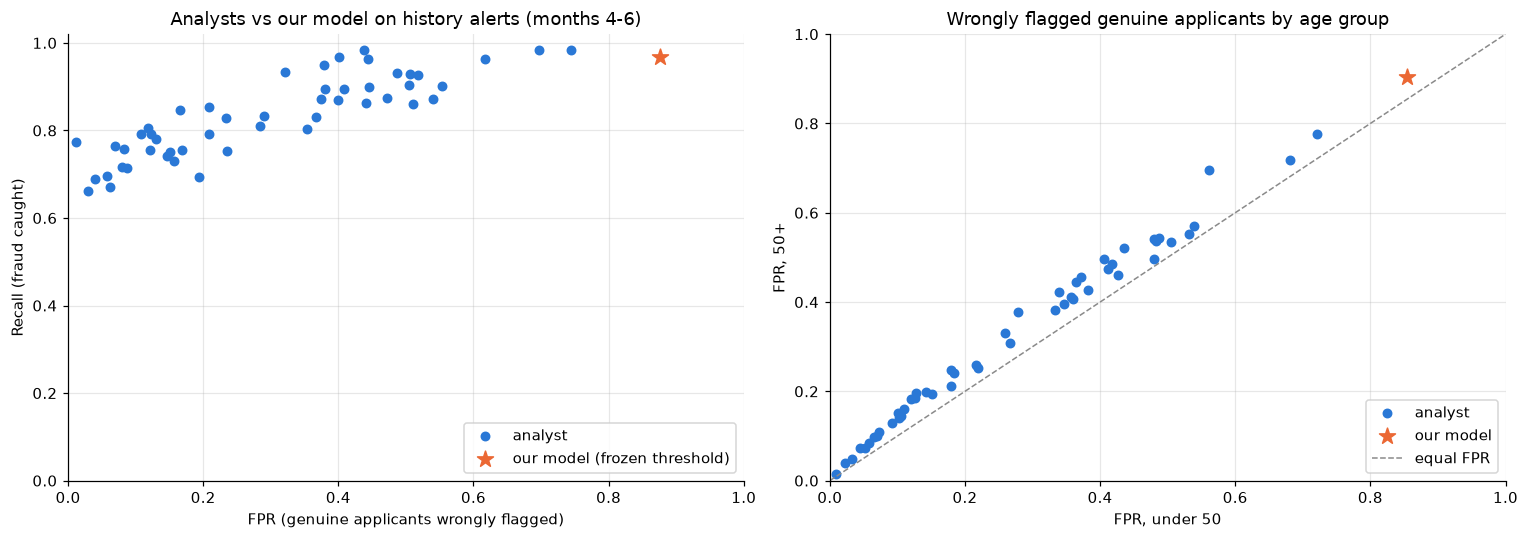

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: each analyst's recall and FPR, with our model's threshold for comparison
ax = axes[0]
ax.scatter(analyst_profile['FPR'], analyst_profile['recall'], color=BLUE, s=30, label='analyst')
ax.scatter(our_model['FPR'], our_model['recall'], color=ORANGE, s=120, marker='*', label='our model (frozen threshold)')
ax.set_xlabel('FPR (genuine applicants wrongly flagged)')
ax.set_ylabel('Recall (fraud caught)')
ax.set_title('Analysts vs our model on history alerts (months 4-6)')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc='lower right')

# Right: FPR for each age group; points above the line flag older applicants more often
ax = axes[1]
ax.scatter(analyst_profile['FPR under 50'], analyst_profile['FPR 50+'], color=BLUE, s=30, label='analyst')
ax.scatter(our_model['FPR under 50'], our_model['FPR 50+'], color=ORANGE, s=120, marker='*', label='our model')
ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1, label='equal FPR')
ax.set_xlabel('FPR, under 50')
ax.set_ylabel('FPR, 50+')
ax.set_title('Wrongly flagged genuine applicants by age group')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [11]:
# The 5 most and least accurate analysts
pd.concat([analyst_profile.sort_values('accuracy', ascending=False).head(5),
           analyst_profile.sort_values('accuracy').head(5)]).round(3)

,accuracy,recall,FPR,FPR 50+,FPR under 50,predictive equality,agrees with model
analyst,,,,,,,
standard#38,0.962,0.775,0.012,0.016,0.009,0.539,0.216
standard#33,0.933,0.662,0.029,0.040,0.022,0.551,0.217
standard#25,0.927,0.690,0.040,0.048,0.034,0.694,0.228
standard#23,0.912,0.696,0.057,0.074,0.045,0.608,0.243
standard#39,0.910,0.765,0.069,0.085,0.058,0.676,0.262
standard#4,0.345,0.983,0.744,0.776,0.721,0.929,0.766
standard#3,0.387,0.983,0.697,0.718,0.681,0.948,0.734
standard#32,0.454,0.964,0.618,0.695,0.561,0.806,0.688
standard#42,0.503,0.901,0.553,0.571,0.539,0.944,0.618


**Findings**

- **The analysts differ hugely.** On the history alerts, recall ranges from 0.66 to 0.98 and FPR from 1% to 74%. The careful ones (e.g. `standard#38`: FPR 1%, recall 0.78) and the trigger-happy ones (e.g. `standard#4`: flags 74% of genuine alerts, recall 0.98) make very different trade-offs, so *which* analyst gets a case matters, not just *whether* a human sees it.
- **Accuracy alone is misleading here.** Only 12-16% of alerts are fraud, so calling every alert genuine would already score about 0.87 accuracy, and many analysts score below that. Recall, FPR and, later, cost are the useful measures.
- **Every analyst flags older applicants more often.** All 50 have a higher FPR for 50+ than for under 50 (predictive equality 0.54-0.97, mean 0.79). The most accurate analysts are among the most age-biased (`standard#38`: 0.54, `standard#33`: 0.55), so routing cases to the "best" analyst could make age disparities worse. This is the fairness question for the routing policies.
- **Our model's frozen threshold doesn't suit alerts.** It was set to flag 5% of *all* genuine applications, but every alert already looks risky, so it flags 81-89% of alerts (FPR 0.87 on history). The review policies therefore need a threshold chosen for alerts, picked on the history months.
- **Our model still ranks alerts slightly better than Feedzai's alert model** (ROC-AUC 0.70-0.71 vs 0.68; PR-AUC 0.29-0.35 vs 0.28-0.33), but separating fraud among alerts is much harder than among all applications (ROC-AUC 0.89 in notebook 02). The best analysts beat the model within alerts, which is what makes human review worth simulating.

## **6. Who Should Decide Each Alert?**
We now simulate how a bank could split the month-7 alerts between our model and the analysts, when analysts can only review part of them.

**Cost.** A missed fraud costs more than a false alarm on a genuine customer. We don't know a bank's real costs, so the cost of one missed fraud is set to **5, 10, 20 or 50 false alarms** (the *cost ratio*), and every result is checked across all four:

> cost = cost ratio × missed fraud + false alarms

Costs are reported per 1,000 alerts, in units of one false alarm. The main charts use a ratio of 10.

**Seeds.** Every simulation is run 5 times: run *s* uses our model's seed *s* and random seed *s* for any random choices (which alerts, which analyst). Results are the mean over the 5 runs.

In [12]:
COST_RATIOS = [5, 10, 20, 50]
MAIN_RATIO = 10
CAPACITIES = np.round(np.arange(0, 1.01, 0.1), 1)   # share of month-7 alerts analysts can review

test = alerts['month'].isin(TEST_MONTHS)
y_test = alerts.loc[test, TARGET].to_numpy()
age_50_plus_test = alerts.loc[test, 'customer_age'].to_numpy() >= 50
analyst_decisions_test = expert_predictions.loc[test].to_numpy().astype(bool)   # alerts x analysts
analyst_decisions_history = expert_predictions.loc[history].to_numpy().astype(bool)


def total_cost(y_true, decisions, ratio):
    missed_fraud = ((y_true == 1) & ~decisions).sum()
    false_alarms = ((y_true == 0) & decisions).sum()
    return ratio * missed_fraud + false_alarms


print(f'{test.sum():,} test alerts (month 7), {y_test.sum()} of them fraud')

4,457 test alerts (month 7), 711 of them fraud


### **6.1 A Threshold for Alerts**
Section 4.1 showed that the frozen threshold flags almost every alert. For each cost ratio and seed we pick a new threshold on the **history months (4-6)**: the one with the lowest cost there. It is then applied unchanged to month 7.

How the threshold is picked (`lowest_cost_threshold` below):
- **Try every cut-off.** The history alerts are sorted by score, highest first. For every k, flagging the top k alerts gives a number of false alarms (genuine alerts in the top k) and missed fraud (fraud alerts below it), and so a cost: cost ratio × missed fraud + false alarms. Running totals down the sorted list give the cost of every cut-off at once.
- **Keep the cheapest.** The threshold is the score of the last alert flagged at the cheapest cut-off; alerts scoring at or above it are flagged. If flagging nothing is cheaper still, nothing is flagged.
- **Example** (5 alerts, cost ratio 10): scores 0.9 (fraud), 0.7 (genuine), 0.6 (fraud), 0.4 (genuine), 0.2 (genuine). Flagging the top 0-5 costs 20, 10, 11, **1**, 2 and 3, so the top 3 are flagged and the threshold is **0.6**.
- **No peeking at month 7.** The threshold is picked on months 4-6 only, separately for each seed, and applied unchanged to month 7; the table shows the mean over the 5 seeds.
- **The scores are not probabilities** (fraud was weighted about 26x in training, notebook 02), so a threshold of 0.81 does not mean an 81% chance of fraud.

In [13]:
def lowest_cost_threshold(y_true, scores, ratio):
    """The cut-off (flag if score >= cut-off) with the lowest cost on these alerts."""
    order = np.argsort(-scores)
    sorted_scores = scores[order]
    is_fraud = y_true[order] == 1
    # flagging the top k alerts, for every k from 1 to all of them
    false_alarms = np.cumsum(~is_fraud)
    missed_fraud = is_fraud.sum() - np.cumsum(is_fraud)
    costs = ratio * missed_fraud + false_alarms
    best = np.argmin(costs)
    if ratio * is_fraud.sum() <= costs[best]:   # flagging nothing is cheaper
        return np.inf
    return sorted_scores[best]


alert_thresholds = {}
rows = []
for ratio in COST_RATIOS:
    for seed in SEEDS:
        history_scores = alerts.loc[history, f'score_seed{seed}'].to_numpy()
        threshold = lowest_cost_threshold(y_history, history_scores, ratio)
        alert_thresholds[(ratio, seed)] = threshold

        test_flags = alerts.loc[test, f'score_seed{seed}'].to_numpy() >= threshold
        rows.append({'cost ratio': ratio, 'seed': seed, 'threshold': threshold,
                     'share flagged (month 7)': test_flags.mean(),
                     'recall (month 7)': test_flags[y_test == 1].mean(),
                     'FPR (month 7)': test_flags[y_test == 0].mean()})

threshold_table = pd.DataFrame(rows).drop(columns='seed').groupby('cost ratio').mean()
threshold_table['frozen threshold (notebook 02)'] = np.mean(list(thresholds.values()))
threshold_table.round(3)

,threshold,share flagged (month 7),recall (month 7),FPR (month 7),frozen threshold (notebook 02)
cost ratio,,,,,
5,0.806,0.199,0.425,0.156,0.475
10,0.673,0.468,0.722,0.420,0.475
20,0.465,0.819,0.946,0.795,0.475
50,0.300,0.942,0.991,0.932,0.475


**Findings**
- **The higher the cost of a missed fraud, the lower the threshold.** At a cost ratio of 5 the model flags 20% of month-7 alerts (threshold 0.81); at 50 it flags 94% (threshold 0.30).
- **The model can't get both high recall and low FPR on alerts.** Catching 95% of fraud means wrongly flagging 80% of genuine alerts (ratio 20), and keeping false alarms to 16% means catching only 43% of fraud (ratio 5). The best analyst catches 78% at a 1.2% FPR, which no threshold comes close to.
- **The threshold is a business choice.** It depends on how the bank weighs missed fraud against false alarms, so the simulation reports all four cost ratios instead of one threshold.
- **The frozen threshold (0.475) behaves like a cost ratio of about 20** on alerts (ratio-20 threshold: 0.465), which is why it flagged 81-89% of them in section 4.1.

### **6.2 The Review Policies**
Each policy decides which month-7 alerts go to an analyst. The model decides the rest with the threshold from 6.1.

| Policy | Alerts sent to analysts | Which analyst |
|---|---|---|
| **AI only** | none | - |
| **Analysts only** | all (ignores capacity) | random, from all 50 |
| **Random alerts** | a random share | random, from all 50 |
| **Highest-risk alerts** | those with the highest model scores | random, from all 50 |
| **Unsure alerts** | those whose score is closest to the threshold, where the model is least sure | random, from all 50 |
| **Unsure alerts, best analysts** | as above | random, from the 10 analysts with the lowest history cost |

"Closest to the threshold" is measured on the log-odds scale, `|logit(score) - logit(threshold)|`, so that a step near 0 or 1 counts as much as a step near the middle. The best 10 analysts are picked on the history months only, separately for each cost ratio. Ten matches the size of FiFAR's analyst teams; each one then reviews at most about 450 month-7 alerts, close to FiFAR's capacity of about 405 per analyst.

In [14]:
POLICIES = ['AI only', 'Analysts only', 'Random alerts', 'Highest-risk alerts',
            'Unsure alerts', 'Unsure alerts, best analysts']
POLICY_COLOURS = {'AI only': '#3d3d3d', 'Analysts only': GREY, 'Random alerts': '#9b6dd6',
                  'Highest-risk alerts': GREEN, 'Unsure alerts': BLUE,
                  'Unsure alerts, best analysts': ORANGE}
ALL_ANALYSTS = np.arange(len(ANALYSTS))

# the 10 analysts with the lowest cost on the history months, for each cost ratio
best_analysts = {}
for ratio in COST_RATIOS:
    history_costs = [total_cost(y_history, analyst_decisions_history[:, j], ratio) for j in ALL_ANALYSTS]
    best_analysts[ratio] = np.argsort(history_costs)[:10]
    print(f'ratio {ratio:2d}: best 10 analysts =', [ANALYSTS[j] for j in best_analysts[ratio]])


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def simulate(policy, capacity, ratio, seed):
    """Final decision on every month-7 alert under one policy. Returns (decisions, alerts reviewed)."""
    rng = np.random.default_rng(seed)
    scores = alerts.loc[test, f'score_seed{seed}'].to_numpy()
    threshold = alert_thresholds[(ratio, seed)]
    decisions = scores >= threshold
    n_alerts = len(scores)
    n_reviewed = int(round(capacity * n_alerts))

    if policy == 'AI only':
        reviewed = np.array([], dtype=int)
    elif policy == 'Analysts only':
        reviewed = np.arange(n_alerts)
    elif policy == 'Random alerts':
        reviewed = rng.choice(n_alerts, size=n_reviewed, replace=False)
    elif policy == 'Highest-risk alerts':
        reviewed = np.argsort(-scores)[:n_reviewed]
    elif policy in ('Unsure alerts', 'Unsure alerts, best analysts'):
        distance = np.abs(logit(scores) - logit(min(threshold, 1)))
        reviewed = np.argsort(distance)[:n_reviewed]
    else:
        raise ValueError(f'unknown policy: {policy}')

    pool = best_analysts[ratio] if policy == 'Unsure alerts, best analysts' else ALL_ANALYSTS
    assigned = rng.choice(pool, size=len(reviewed))
    decisions[reviewed] = analyst_decisions_test[reviewed, assigned]
    return decisions, len(reviewed)


def policy_metrics(decisions, ratio):
    fraud = y_test == 1
    genuine = y_test == 0
    fpr_50_plus = decisions[genuine & age_50_plus_test].mean()
    fpr_under_50 = decisions[genuine & ~age_50_plus_test].mean()
    return {
        'cost per 1,000 alerts': total_cost(y_test, decisions, ratio) / len(decisions) * 1000,
        'recall': decisions[fraud].mean(),
        'FPR': decisions[genuine].mean(),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': min(fpr_50_plus, fpr_under_50) / max(fpr_50_plus, fpr_under_50),
    }

ratio  5: best 10 analysts = ['standard#38', 'standard#39', 'standard#17', 'standard#37', 'standard#10', 'standard#25', 'standard#33', 'standard#21', 'standard#23', 'standard#48']
ratio 10: best 10 analysts = ['standard#38', 'standard#48', 'standard#10', 'standard#39', 'standard#37', 'standard#40', 'standard#7', 'standard#21', 'standard#17', 'standard#12']
ratio 20: best 10 analysts = ['standard#41', 'standard#28', 'standard#7', 'standard#43', 'standard#46', 'standard#48', 'standard#40', 'standard#38', 'standard#10', 'standard#18']
ratio 50: best 10 analysts = ['standard#41', 'standard#28', 'standard#46', 'standard#43', 'standard#7', 'standard#3', 'standard#4', 'standard#32', 'standard#6', 'standard#24']


In [15]:
rows = []
for ratio in COST_RATIOS:
    for policy in POLICIES:
        for capacity in CAPACITIES:
            for seed in SEEDS:
                decisions, n_reviewed = simulate(policy, capacity, ratio, seed)
                rows.append({'cost ratio': ratio, 'policy': policy, 'capacity': capacity, 'seed': seed,
                             'share reviewed': n_reviewed / len(decisions),
                             **policy_metrics(decisions, ratio)})

simulation = pd.DataFrame(rows)
results = simulation.drop(columns='seed').groupby(['cost ratio', 'policy', 'capacity'], sort=False).mean()
print(f'{len(simulation):,} simulations')

1,320 simulations


### **6.3 Fraud Caught and Cost vs Analyst Capacity**
Capacity is the share of month-7 alerts the analysts can review. *AI only* and *Analysts only* don't depend on capacity, so they are flat lines.

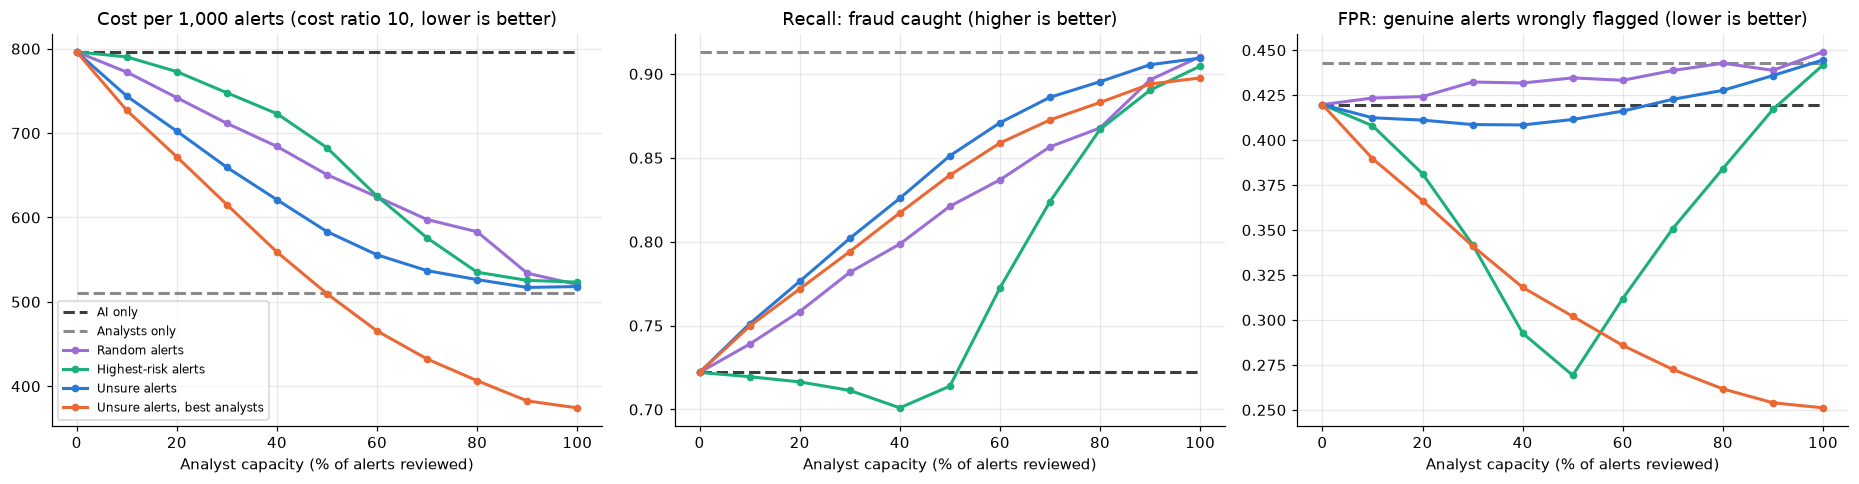

In [16]:
main = results.loc[MAIN_RATIO].reset_index()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for policy in POLICIES:
    part = main[main['policy'] == policy]
    style = dict(color=POLICY_COLOURS[policy], linewidth=2, marker='o', markersize=4, label=policy)
    if policy in ('AI only', 'Analysts only'):
        style.update(marker=None, linestyle='--')
    axes[0].plot(part['capacity'] * 100, part['cost per 1,000 alerts'], **style)
    axes[1].plot(part['capacity'] * 100, part['recall'], **style)
    axes[2].plot(part['capacity'] * 100, part['FPR'], **style)

axes[0].set_title(f'Cost per 1,000 alerts (cost ratio {MAIN_RATIO}, lower is better)')
axes[1].set_title('Recall: fraud caught (higher is better)')
axes[2].set_title('FPR: genuine alerts wrongly flagged (lower is better)')
for ax in axes:
    ax.set_xlabel('Analyst capacity (% of alerts reviewed)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
# Cost per 1,000 alerts for every cost ratio, at a few capacities
table = results['cost per 1,000 alerts'].unstack('capacity')[[0.1, 0.3, 0.5, 0.7, 0.9]]
table.columns = [f'{int(c * 100)}% reviewed' for c in table.columns]
table.round(0)

10% reviewed  30% reviewed  \
cost ratio policy                                                     
5          AI only                              590.0         590.0   
           Analysts only                        441.0         441.0   
           Random alerts                        579.0         550.0   
           Highest-risk alerts                  582.0         510.0   
           Unsure alerts                        549.0         486.0   
           Unsure alerts, best analysts         528.0         422.0   
10         AI only                              796.0         796.0   
           Analysts only                        511.0         511.0   
           Random alerts                        772.0         712.0   
           Highest-risk alerts                  790.0         748.0   
           Unsure alerts                        744.0         659.0   
           Unsure alerts, best analysts         727.0         615.0   
20         AI only                              840.0         840.0   
           Analysts only                        649.0         649.0   
           Random alerts                        824.0         784.0   
           Highest-risk alerts                  838.0         808.0   
           Unsure alerts                        807.0         741.0   
           Unsure alerts, best analysts         792.0         703.0   
50         AI only                              853.0         853.0   
           Analysts only                       1065.0        1065.0   
           Random alerts                        877.0         916.0   
           Highest-risk alerts                  864.0         873.0   
           Unsure alerts                        848.0         923.0   
           Unsure alerts, best analysts         819.0         771.0   

                                         50% reviewed  70% reviewed  \
cost ratio policy                                                     
5          AI only                              590.0         590.0   
           Analysts only                        441.0         441.0   
           Random alerts                        517.0         485.0   
           Highest-risk alerts                  454.0         435.0   
           Unsure alerts                        450.0         433.0   
           Unsure alerts, best analysts         346.0         287.0   
10         AI only                              796.0         796.0   
           Analysts only                        511.0         511.0   
           Random alerts                        651.0         598.0   
           Highest-risk alerts                  683.0         576.0   
           Unsure alerts                        583.0         537.0   
           Unsure alerts, best analysts         510.0         432.0   
20         AI only                              840.0         840.0   
           Analysts only                        649.0         649.0   
           Random alerts                        742.0         710.0   
           Highest-risk alerts                  784.0         761.0   
           Unsure alerts                        710.0         680.0   
           Unsure alerts, best analysts         633.0         583.0   
50         AI only                              853.0         853.0   
           Analysts only                       1065.0        1065.0   
           Random alerts                        939.0        1001.0   
           Highest-risk alerts                  948.0        1053.0   
           Unsure alerts                       1004.0        1073.0   
           Unsure alerts, best analysts         750.0         735.0   

                                         90% reviewed  
cost ratio policy                                      
5          AI only                              590.0  
           Analysts only                        441.0  
           Random alerts                        454.0  
           Highest-risk alerts                  438.0  
           

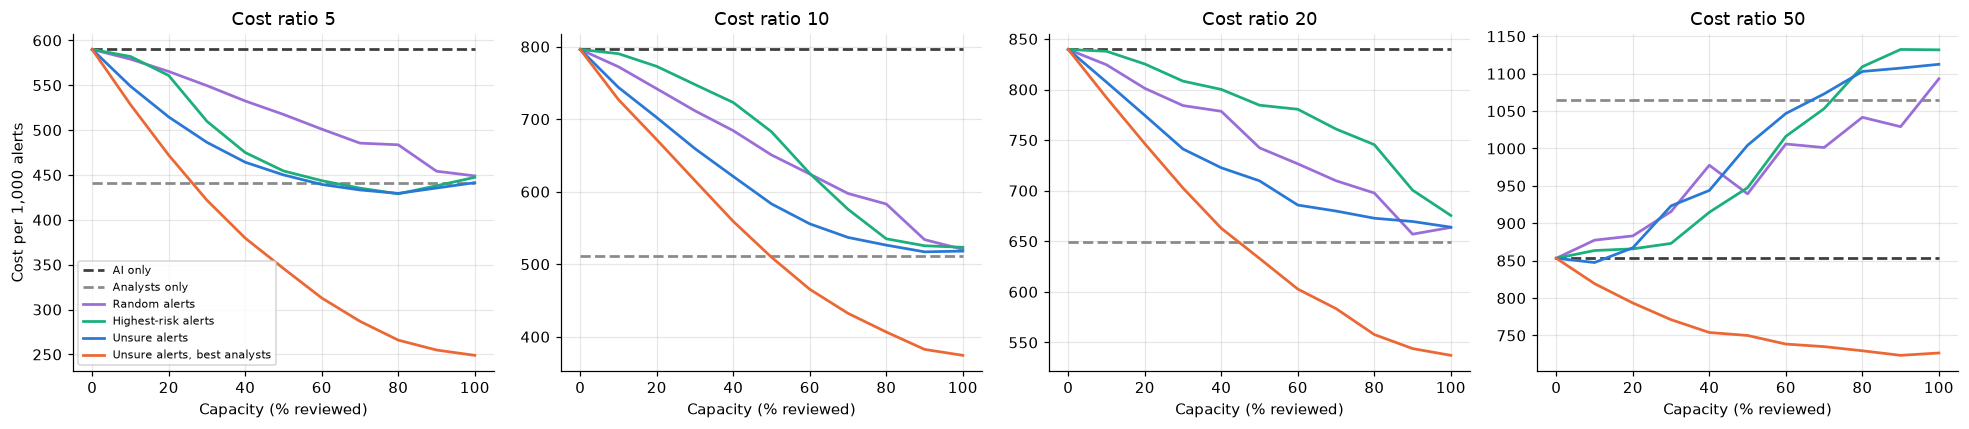

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for ax, ratio in zip(axes, COST_RATIOS):
    part_ratio = results.loc[ratio].reset_index()
    for policy in POLICIES:
        part = part_ratio[part_ratio['policy'] == policy]
        style = dict(color=POLICY_COLOURS[policy], linewidth=1.8, label=policy)
        if policy in ('AI only', 'Analysts only'):
            style.update(linestyle='--')
        ax.plot(part['capacity'] * 100, part['cost per 1,000 alerts'], **style)
    ax.set_title(f'Cost ratio {ratio}')
    ax.set_xlabel('Capacity (% reviewed)')
axes[0].set_ylabel('Cost per 1,000 alerts')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Findings**

- **A threshold set for alerts works far better than the frozen one.** With a cost ratio of 10, the new threshold flags 47% of month-7 alerts and catches 72% of the fraud, instead of flagging 81-89%. The higher a missed fraud costs, the lower the threshold and the more the model flags (20% of alerts at a ratio of 5, 94% at 50).
- **Human review cuts cost, and more capacity cuts it further.** With a cost ratio of 10, AI only costs 796 per 1,000 alerts. Every policy that sends alerts to analysts gets cheaper as capacity grows, down to about 520 when analysts review everything.
- **Which alerts go to analysts matters.** Sending the alerts the model is **least sure about** is the cheapest way to use random analysts at every capacity: at 50% capacity it costs 583, against 651 for random alerts and 683 for the highest-risk alerts. Sending the highest-risk alerts is the worst choice at low capacity: the model would flag those anyway, so analysts mostly clear some of them, which lowers false alarms but also lets fraud through (recall falls from 0.72 to 0.70 at 40% capacity).
- **Which analyst gets the alert matters even more.** Sending the unsure alerts to the 10 analysts with the lowest history cost is the cheapest of the capacity-limited policies at every capacity (10-100%) and every cost ratio. At 50% capacity it already matches analysts reviewing *every* alert (510 vs 511), and at full capacity it costs 374, 27% less than analysts only. It also has the most stable results across the 5 runs (standard deviation 10 vs 16-20).
- **When missed fraud is very expensive, random analysts make things worse.** At a cost ratio of 50 the model flags 94% of alerts, catching almost all fraud. Analysts flag less, so handing them alerts lets fraud through: analysts only (1,065) costs more than AI only (853). Only the best-analysts policy clearly beats AI only at this ratio (727 at full capacity).
- Differences of about 20 per 1,000 alerts are within the run-to-run spread, so only larger gaps should be read as real.

### **6.4 Fairness of Each Policy**
FPR for each age group and predictive equality (lower group FPR / higher group FPR, 1 = equal), as in notebook 02 and section 5, at a cost ratio of 10.

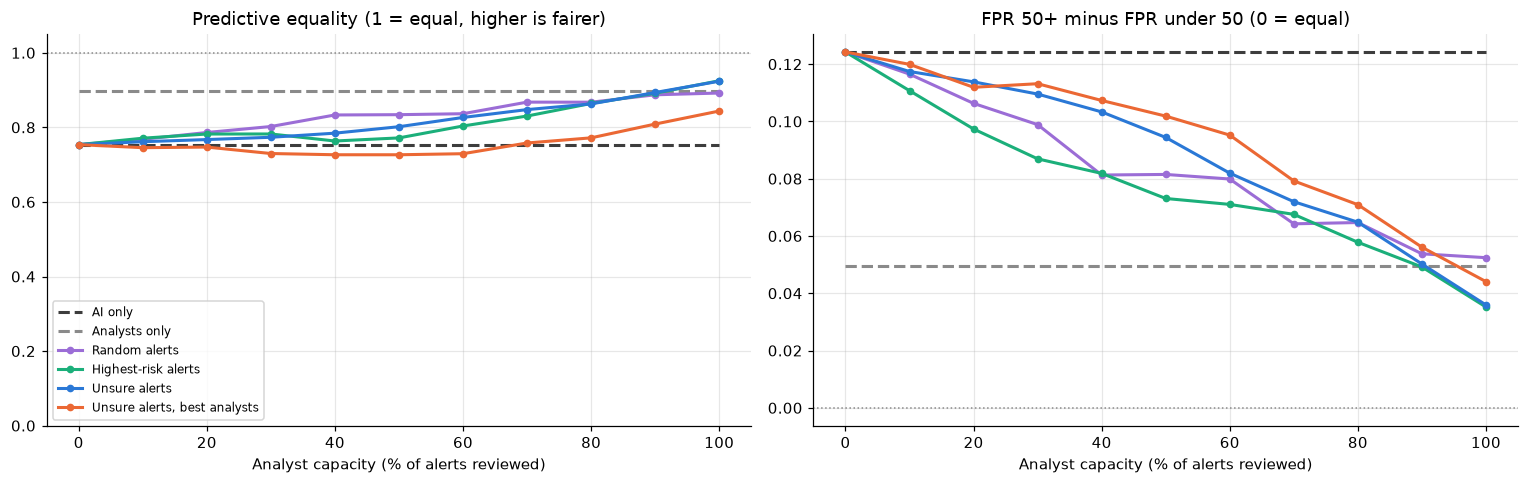

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for policy in POLICIES:
    part = main[main['policy'] == policy]
    style = dict(color=POLICY_COLOURS[policy], linewidth=2, marker='o', markersize=4, label=policy)
    if policy in ('AI only', 'Analysts only'):
        style.update(marker=None, linestyle='--')
    axes[0].plot(part['capacity'] * 100, part['predictive equality'], **style)
    axes[1].plot(part['capacity'] * 100, part['FPR 50+'] - part['FPR under 50'], **style)

axes[0].axhline(1, color=GREY, linewidth=1, linestyle=':')
axes[0].set_title('Predictive equality (1 = equal, higher is fairer)')
axes[0].set_ylim(0, 1.05)
axes[1].axhline(0, color=GREY, linewidth=1, linestyle=':')
axes[1].set_title('FPR 50+ minus FPR under 50 (0 = equal)')
for ax in axes:
    ax.set_xlabel('Analyst capacity (% of alerts reviewed)')
axes[0].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

In [20]:
# Every policy at 50% capacity (cost ratio 10), mean over the 5 runs
columns = ['cost per 1,000 alerts', 'recall', 'FPR', 'FPR 50+', 'FPR under 50', 'predictive equality']
at_half = main[main['capacity'] == 0.5].set_index('policy')[columns]
at_half.round(3)

,"cost per 1,000 alerts",recall,FPR,FPR 50+,FPR under 50,predictive equality
policy,,,,,,
AI only,796.141,0.722,0.420,0.506,0.382,0.754
Analysts only,510.792,0.913,0.443,0.477,0.428,0.896
Random alerts,650.662,0.821,0.435,0.491,0.410,0.834
Highest-risk alerts,682.656,0.714,0.269,0.320,0.247,0.772
Unsure alerts,583.217,0.851,0.411,0.477,0.383,0.802
"Unsure alerts, best analysts",509.625,0.840,0.302,0.373,0.271,0.727


**Findings**

- **Every policy is harder on older applicants.** In all of them, genuine applicants aged 50+ are wrongly flagged more often than those under 50. AI only has a predictive equality of 0.75 (FPR 0.51 vs 0.38 at a cost ratio of 10); analysts only is the fairest at 0.90.
- **Sending alerts to random analysts makes the system fairer as capacity grows.** For the unsure-alerts policy, predictive equality rises from 0.75 with no review to 0.80 at 50% capacity and 0.92 at full capacity, and the FPR gap between the age groups shrinks from 12 to 4 percentage points.
- **The cheapest policy is the least fair by the ratio measure.** Sending unsure alerts to the best 10 analysts gives the lowest predictive equality (0.73 at 50% capacity, below AI only), because the most accurate analysts are among the most age-biased (section 5). But it also flags far fewer genuine applicants in *both* groups (FPR 0.37 for 50+ and 0.27 under 50, against 0.48 and 0.38 for unsure alerts to random analysts), so in absolute terms its FPR gap (10 points) is smaller than AI only's (12) and only slightly larger than the other hybrid policies' (7-9).
- **So there is a cost-fairness trade-off.** The best analysts give the biggest saving but keep the age disparity; spreading alerts across all analysts is fairer but costs more. A bank could pick the best analysts on cost *and* fairness, or check their age-group error rates regularly.

## **7. Summary**

### The question
A bank's fraud system flags suspicious account applications (**alerts**) for human fraud analysts to check, but there are never enough analysts to check every alert. **Which alerts should the computer model decide on its own, and which should a person review?**

We tested this on 4,457 alerts from one month (month 7) of a realistic synthetic bank dataset, using our fraud model and the recorded decisions of 50 simulated fraud analysts.

### How we measured "cost"
A fraud system makes two kinds of mistakes:
- **Missed fraud**: a fraudster gets an account. Expensive.
- **False alarm**: a genuine customer is treated as a fraudster. Cheaper, but it annoys customers and wastes staff time.

We don't know a bank's real figures, so we assumed **one missed fraud costs as much as 10 false alarms**, and checked that the conclusions hold at 5, 20 and 50 too. Costs below are per 1,000 alerts, in "false alarm" units: lower is better.

### What we found

**1. The cases that reach analysts are the hardest ones.**
The bank's first screening step sends only about **5% of applications** for review. About **12% of those are fraud**, ten times the 1.1% of all applications. But this screen already misses **about half of all fraud**, which never reaches an analyst, so no review process can catch it.

**2. On these hard cases, our model is much weaker than people.**
Every alert already looks suspicious, so the model finds it hard to tell fraud from genuine customers. To catch **72% of the fraud**, it has to wrongly flag **42% of genuine customers**. The best analyst catches **78% of fraud while wrongly flagging only 1.2%** of genuine customers; at that same low rate of false alarms, the model would catch just **9%**. **All 50 analysts** do better than the model on these cases.

**3. Sending cases to analysts cuts costs, and the right cases and right analysts matter most.**

| How alerts are handled | Cost per 1,000 alerts |
|---|---|
| Model decides every alert | **796** |
| Analysts (picked at random) decide every alert | 511 |
| Half the alerts reviewed: random cases, random analysts | 651 |
| Half reviewed: the cases the model is **least sure** about, random analysts | 583 |
| Half reviewed: the cases the model is least sure about, **the 10 best analysts** | **510** |
| All reviewed by the 10 best analysts, least-sure cases first | **374** |

- Letting analysts review the half of alerts the model is **least sure about** saves **27%** compared with the model alone (583 vs 796).
- Giving those cases to the **10 analysts with the best track record** saves **36%** (510 vs 796), and **matches having analysts review every single alert** (511) with **half the workload**.
- In that setup, the system catches **84% of fraud instead of 72%**, and wrongly flags **30% of genuine customers instead of 42%**.
- This ranking holds whether a missed fraud is worth 5, 10 or 20 false alarms.

**4. When missed fraud is extremely costly, untrained review can backfire.**
If a missed fraud is worth 50 false alarms, the model flags almost everything to be safe (94% of alerts). Analysts picked at random let more fraud through, so they make things **worse**: 1,065 vs 853 for the model alone. Only the **best analysts** still improve on the model (723).

**5. Every approach treats older customers less fairly, and the cheapest is not the fairest.**
Genuine customers **aged 50 or over are wrongly flagged more often** under every approach. With the model alone, **51% of genuine older customers** among the alerts are wrongly flagged, against **38% of younger ones**. Spreading cases across many analysts narrows this gap, from **12 to 4 percentage points** when all alerts are reviewed. The **best analysts are also among the most biased by age**: with them, older customers are still wrongly flagged more often (**37% vs 27%**), even though both groups are wrongly flagged less than with the model alone.

### What we recommend for the bank
1. **Use the model as a triage step, not the final decision-maker.** Let it decide the alerts it is confident about (clear approvals and clear blocks), and **send the alerts it is least sure about to analysts**.
2. **Route those cases to the analysts with the best track record.** This gives the largest savings: as good as reviewing every alert, with half the work.
3. **Set the model's cut-off from the bank's own costs.** The right setting depends on how much a missed fraud costs compared with a false alarm, and should be reviewed regularly because fraud patterns change.
4. **Monitor fairness by age group.** Track how often each analyst, and the system overall, wrongly flags older vs younger customers, and take it into account when choosing which analysts get the most cases.

### Limitations
- The analysts are **simulated** from a public research dataset, not real bank staff.
- Costs are **relative** (a missed fraud worth 5-50 false alarms); real figures, and the cost of analysts' time, would change the exact numbers.
- Each analyst's personal workload limit is not modelled, only the share of alerts that can be reviewed overall.
- Results come from **one month** of alerts (4,457), and about half of all fraud is never alerted at all, which no review strategy can fix.